# VAD：解码器微调

[English](01_finetune.ipynb) | 简体中文

## Goal / 目标

使用与 CLI 相同的实现。默认合成 CPU 教程验证工程流程，不代表语音质量。真实 Silero 仅微调选中 decoder；本教程的小型随机特征映射**不是预训练 Silero**。

## Setup / 环境

本地在对应 kernel 安装 `.[vad,notebooks,publish]`。下一格只在 Colab 安装。VAD 不依赖 Transformers。私有录音和长时间任务的输出放在持久存储；Notebook 不上传数据。

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    ROOT = Path("/content/advai-notebooks")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/advai-x/advai-notebooks.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}[vad,notebooks,publish]"], check=True)
else:
    ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
                if (path / "pyproject.toml").is_file())
print("Repository and VAD environment ready.")

Repository and VAD environment ready.


### 参数与导入

全新输出路径支持完整重跑。YAML 记录 seed、阈值、采样率和 optimizer。

In [2]:
import json
import uuid
import torch
import matplotlib.pyplot as plt
from IPython.display import Audio, Markdown, display
from advai_notebooks.vad.config import load_config
from advai_notebooks.vad.data import load_data, prepare_data
from advai_notebooks.vad.model import VADModel
from advai_notebooks.vad.pipeline import run
from advai_notebooks.vad.publish import publish
from advai_notebooks.vad.visualize import plot_detection
from advai_notebooks.common.runtime import setup

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
cfg = load_config(ROOT / "configs/vad/smoke.yaml", ROOT)
cfg.output_dir = f"outputs/vad/01_finetune-{uuid.uuid4().hex[:8]}"
print({"backend": cfg.model.id, "sample_rate": cfg.model.sample_rate,
       "seed": cfg.training.seed, "frame_seconds": 0.032})

{'backend': 'tiny', 'sample_rate': 16000, 'seed': 42, 'frame_seconds': 0.032}


## Steps / 步骤

### 1. 校验音频与完整区间标注

所有未标注区域视为负例而非未知。`[]` 明确表示无语音。先按原录音划分再切片；这些样例是正弦音，不是真人语音。

In [3]:
rows, summary = load_data(cfg)
validator = VADModel(cfg.model, setup(cfg))
prepared = prepare_data(rows, validator, cfg)
print({"splits": summary["splits"],
       "prepared": {key: len(value) for key, value in prepared.items()}})
for row in rows[:3]:
    print({"id": row["id"], "split": row["split"], "speech_segments": row["speech_segments"]})
display(Audio(rows[0]["waveform"], rate=cfg.model.sample_rate))
del validator, prepared

{'splits': {'train': 4, 'validation': 2, 'test': 2}, 'prepared': {'train': 4, 'validation': 2, 'test': 2}}
{'id': 'one', 'split': 'train', 'speech_segments': [{'start': 0.32, 'end': 0.8}, {'start': 1.12, 'end': 1.6}]}
{'id': 'two', 'split': 'train', 'speech_segments': [{'start': 0.32, 'end': 0.8}, {'start': 1.12, 'end': 1.6}]}
{'id': 'three', 'split': 'train', 'speech_segments': []}


### 2. 训练并模拟 epoch 边界中断

Checkpoint 包含 optimizer 与 RNG；冻结特征不接收梯度。

In [4]:
class TutorialInterruption(Exception):
    pass

def stop_after_first_epoch(epoch, state):
    if epoch == 1:
        raise TutorialInterruption("Epoch-one checkpoint saved.")

try:
    run(cfg, callbacks=(stop_after_first_epoch,))
except TutorialInterruption as error:
    print(error)
latest = cfg.path(cfg.output_dir) / "latest"
assert (latest / "state.json").is_file()

Epoch-one checkpoint saved.


### 3. 恢复、选模与仅验证集校准

BCE 选权重，验证集区间 F1 选阈值网格；test 仅报告。表格在同一选中政策下对比权重，不是语音 benchmark。

In [5]:
report = run(cfg, resume=latest)
assert report["training"]["epoch"] == cfg.training.epochs
assert report["calibration"]["split"] == "validation"
baseline = report["baseline_test"]["metrics"]
selected_metrics = report["finetuned_test"]["metrics"]
table = "| Metric | Baseline | Selected |\n| --- | ---: | ---: |\n"
for metric in ("bce", "precision", "recall", "f1", "miss_rate", "false_alarm_rate", "segment_f1"):
    table += f"| {metric} | {baseline[metric]:.4f} | {selected_metrics[metric]:.4f} |\n"
display(Markdown(table))
print({"selected_epoch": report["training"]["best_epoch"],
       "calibration": report["calibration"]["selected"]})

| Metric | Baseline | Selected |
| --- | ---: | ---: |
| bce | 0.6921 | 0.6888 |
| precision | 0.4800 | 0.4800 |
| recall | 1.0000 | 1.0000 |
| f1 | 0.6486 | 0.6486 |
| miss_rate | 0.0000 | 0.0000 |
| false_alarm_rate | 1.0000 | 1.0000 |
| segment_f1 | 0.6486 | 0.6486 |


{'selected_epoch': 2, 'calibration': {'threshold': 0.4, 'exit_threshold': 0.25, 'segment_f1': 0.3870967741935484}}


### 4. 重载并检查时间轴

上行为波形，中行为概率与阈值，下行为检测区间与合成标签。差异说明必须在真实 held-out 数据上评估。

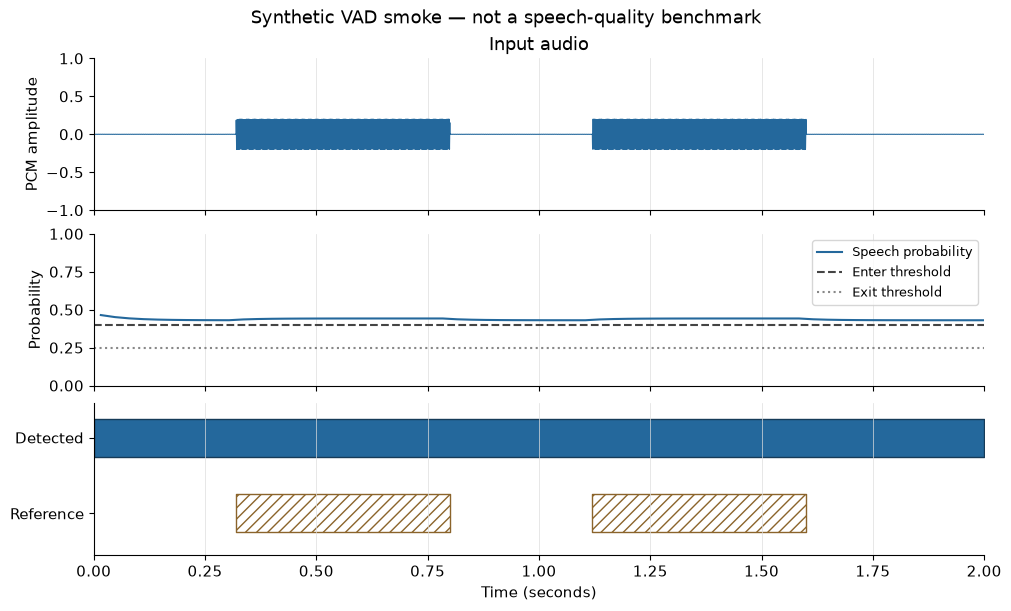

In [6]:
model = VADModel.load(report["export"], "cpu")
detection = model.detect(rows[-1]["audio"])
figure = plot_detection(detection, model.settings, rows[-1]["speech_segments"])
figure.suptitle("Synthetic VAD smoke — not a speech-quality benchmark")
figure.savefig(cfg.path(cfg.output_dir) / "timeline.png", dpi=140)
plt.show()

## Checks / 检查

检查重载一致性与离线发布预览；推理包不含录音或训练状态。

In [7]:
reloaded = VADModel.load(report["export"], "cpu")
assert model.detect(rows[-1]["audio"]) == reloaded.detect(rows[-1]["audio"])
for name, value in model.model.state_dict().items():
    assert torch.equal(value, reloaded.model.state_dict()[name])
plan = publish(report["export"], "example/vad-smoke", dry_run=True)
names = [item["path"] for item in plan["files"]]
assert not any(name.endswith((".wav", ".jsonl", ".pt")) for name in names)
print({"reload_equal": True, "publish": plan["status"], "files": len(names)})

{'reload_equal': True, 'publish': 'dry_run', 'files': 3}


## Next Steps / 下一步

阅读[完整指南](../../docs/vad.zh-CN.md)。真实训练复制 `configs/vad/silero.yaml` 到被忽略的 `configs/local/`，使用授权、完整标注音频，按原录音分组。不要用正弦音训练真实模型。STT 推理按源偏移合并转写；TTS 可检查首尾静音，但不自动删除句中停顿。这里不证明 GPU/Colab 适配、实时性能或目标场景语音质量。